<a href="https://colab.research.google.com/github/Janeferdinant/Machine-learning-Course/blob/master/CNN_Identify_the_Digits_%28MNIST%29.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Run note (2026-10-14).** The outputs stored below come from one top-to-bottom run on a CPU (no GPU), with the settings exactly as written in the training cell: batch size 10, 5 epochs, the full 60,000 training images, validated on the 10,000 test images. The architecture is unchanged. The numbers are not seeded, so a new run will differ a little. Settings, hardware and timing are in `docs/runs/2026-10-14-cnn-mnist.md`.
>
> Three cells were adjusted so that the notebook runs outside Colab: the `!pip install` line is now a comment, the personal-image cells (`2.jpeg`, not in this repository) are skipped when the file is missing, and `skimage.io.imshow` was replaced by `matplotlib`. The network diagram needs Graphviz and prints a note when it is not installed.

In [1]:
# Packages: see requirements.txt (tensorflow, keras, numpy, matplotlib, scikit-learn). On Colab they are already installed.


In [2]:
import keras
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D
from keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt


In [3]:
# the data, split between train and test sets
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)


(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


In [4]:
np.set_printoptions(linewidth=np.nan)
print(x_train[12])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0  12  99  91 142 155 246 182 155 155 155 155 131  52   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0 138 254 254 254 254 254 254 254 254 254 254 254 252 210 122  33   0   0   0   0   0   0   0   0   0]
 [  0   0   0 220 254 254 254 235 189 189 189 189 150 189 205 254 254 254  75   0   0   0   0   0   0   0   0   0]
 [  0   0   0  35  74  35  35  25   0   0   0   0   0   0  13 224 254 254 153   

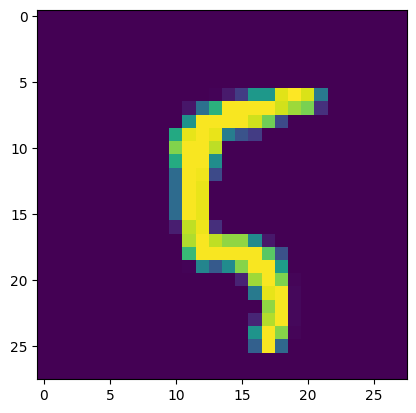

In [5]:
digit = x_train[100]
plt.imshow(digit)
plt.show()

In [6]:
print(x_train[5])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  13  25 100 122   7   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0  33 151 208 252 252 252 146   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  40 152 244 252 253 224 211 252 232  40   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  15 152 239 252 252 252 216  31  37 252 25

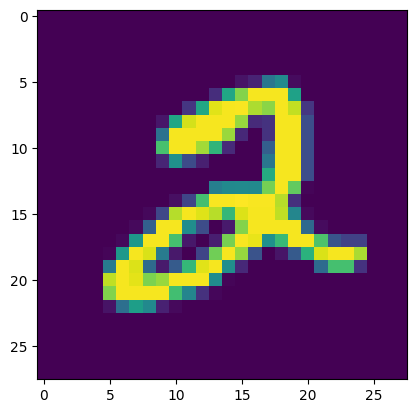

In [7]:
digit = x_train[5]
plt.imshow(digit)
plt.show()

In [8]:
print(x_train[1515])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  13 220  75   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  12 183 251  64   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   4 183 254 193   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 101 254 240  33   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 106 250 254  67   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  69 249 249 113   4   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0  67 254 254 146   0   

In [9]:
# Optional: show your own handwritten digit. 2.jpeg is a personal image that is not in this repository,
# so this cell is skipped unless you add your own file with that name next to the notebook.
import os
if os.path.exists("2.jpeg"):
    plt.imshow(plt.imread("2.jpeg"))
    plt.show()
else:
    print("2.jpeg not found: skipping the personal-image example")


2.jpeg not found: skipping the personal-image example


In [10]:
# Same optional personal image, shown with matplotlib (replaces scikit-image's io.imshow, which is deprecated)
if os.path.exists("2.jpeg"):
    plt.imshow(plt.imread("2.jpeg"), cmap="gray")
    plt.show()
else:
    print("2.jpeg not found: skipping the personal-image example")


2.jpeg not found: skipping the personal-image example


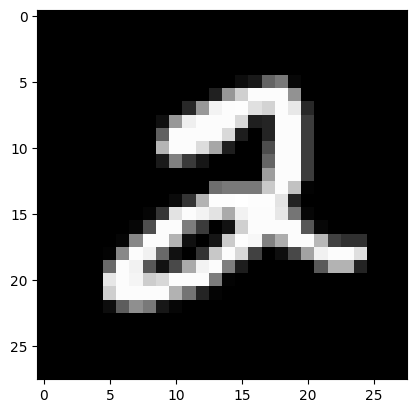

In [11]:
plt.imshow(x_train[5,:,:], cmap="gray")
plt.show()


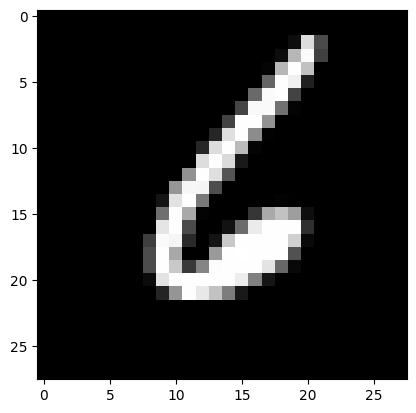

In [12]:
plt.imshow(x_train[1515,:,:], cmap="gray")
plt.show()


In [13]:
x_train.shape

(60000, 28, 28)

In [14]:
x_train = x_train.reshape(x_train.shape[0],-1)
x_train.shape

(60000, 784)

In [15]:
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1) #for creating CNN layer
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1)
input_shape = (28, 28, 1)


In [16]:
x_train.shape

(60000, 28, 28, 1)

In [17]:
y_train

array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

In [18]:
y_train.shape

(60000,)

# **Modelling**

In [19]:
# convert class vectors to binary class matrices
y_train = tf.keras.utils.to_categorical(y_train, num_classes=10)
y_test = tf.keras.utils.to_categorical(y_test, num_classes=10)
print(y_train)

[[0. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 1. 0.]]


In [20]:
y_train.shape

(60000, 10)

In [21]:
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255
x_test /= 255
print('x_train shape:', x_train.shape)
print(x_train.shape[0], 'train samples')
print(x_test.shape[0], 'test samples')


x_train shape: (60000, 28, 28, 1)
60000 train samples
10000 test samples


In [22]:
batch_size = 128
num_classes = 10
epochs = 10

model = Sequential()
model.add(Conv2D(32, kernel_size=(3, 3),activation='relu',input_shape=input_shape, ))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))
model.add(Flatten())
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(num_classes, activation='softmax'))

model.compile(loss=keras.losses.categorical_crossentropy,optimizer='adam',metrics=['accuracy'])

In [23]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 26, 26, 32)        320       
                                                                 
 conv2d_1 (Conv2D)           (None, 24, 24, 64)        18496     
                                                                 
 max_pooling2d (MaxPooling2  (None, 12, 12, 64)        0         
 D)                                                              
                                                                 
 dropout (Dropout)           (None, 12, 12, 64)        0         
                                                                 
 flatten (Flatten)           (None, 9216)              0         
                                                                 
 dense (Dense)               (None, 256)               2359552   
                                                        

In [24]:
# Diagram of the network. This needs the pydot package and the Graphviz program; model.summary() above shows the same layers.
try:
    from keras.utils import plot_model
    from IPython.display import Image
    plot_model(model, to_file='model_plot.png', show_shapes=True, show_layer_names=True)
    display(Image(filename='model_plot.png'))
except Exception as e:
    print("Model diagram skipped (pydot and Graphviz are not installed):", type(e).__name__)


Model diagram skipped (pydot and Graphviz are not installed): ImportError


In [25]:
hist = model.fit(x_train, y_train,epochs=5,batch_size=10,verbose=1,validation_data=(x_test, y_test))
print("The model has successfully trained")

Epoch 1/5


6000/6000 [==============================] - 85s 14ms/step - loss: 0.1420 - accuracy: 0.9558 - val_loss: 0.0445 - val_accuracy: 0.9849
Epoch 2/5
6000/6000 [==============================] - 117s 20ms/step - loss: 0.0668 - accuracy: 0.9799 - val_loss: 0.0373 - val_accuracy: 0.9879
Epoch 3/5
6000/6000 [==============================] - 130s 22ms/step - loss: 0.0517 - accuracy: 0.9844 - val_loss: 0.0376 - val_accuracy: 0.9890
Epoch 4/5
6000/6000 [==============================] - 116s 19ms/step - loss: 0.0421 - accuracy: 0.9873 - val_loss: 0.0335 - val_accuracy: 0.9896
Epoch 5/5
6000/6000 [==============================] - 129s 22ms/step - loss: 0.0340 - accuracy: 0.9894 - val_loss: 0.0297 - val_accuracy: 0.9905
The model has successfully trained


In [26]:
print(hist.history.keys())

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


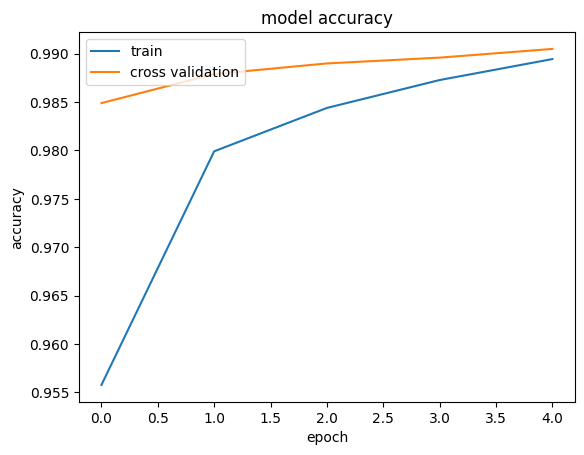

In [27]:
plt.plot(hist.history['accuracy'])
plt.plot(hist.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'cross validation'], loc='upper left')
plt.show()

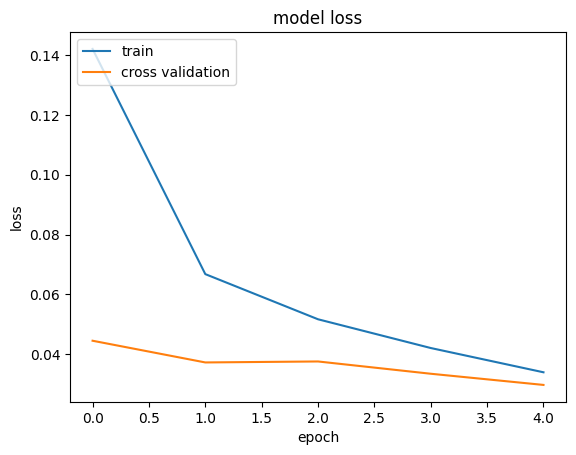

In [28]:
# summarize history for loss
plt.plot(hist.history['loss'])
plt.plot(hist.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'cross validation'], loc='upper left')
plt.show()

In [29]:
model.save('mnist.h5')
print("Saving the model as mnist.h5")

...\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Saving the model as mnist.h5


In [30]:
score = model.evaluate(x_test, y_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 0.029742253944277763
Test accuracy: 0.9904999732971191


In [31]:
y_pred = model.predict(x_test,verbose=1)



313/313 [==============================] - 4s 11ms/step


In [32]:
y_pred = np.argmax(y_pred, axis=1) 

In [33]:
y_pred

array([7, 2, 1, ..., 4, 5, 6], dtype=int64)

In [34]:
y_test = np.argmax(y_test, axis=1) 

In [35]:
y_test

array([7, 2, 1, ..., 4, 5, 6], dtype=int64)

In [36]:
correct_indices = list(np.where(y_pred == y_test)[0])
incorrect_indices = list(np.where(y_pred != y_test)[0])

In [37]:
print(len(correct_indices))
print(len(incorrect_indices))

9905
95


In [38]:
from sklearn.metrics import classification_report,confusion_matrix
report = classification_report(y_test,y_pred)
conf_matrix = confusion_matrix(y_test,y_pred)
print(report)
print(conf_matrix)

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       1.00      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

[[ 975    1    0    0    0    0    2    1    1    0]
 [   1 1134    0    0    0    0    0    0    0    0]
 [   1    2 1023    0    0    0    1    4    0    1]
 [   0    0    3 1002    0    3    0    0    2    0]
 [   0    0    0    0  970   

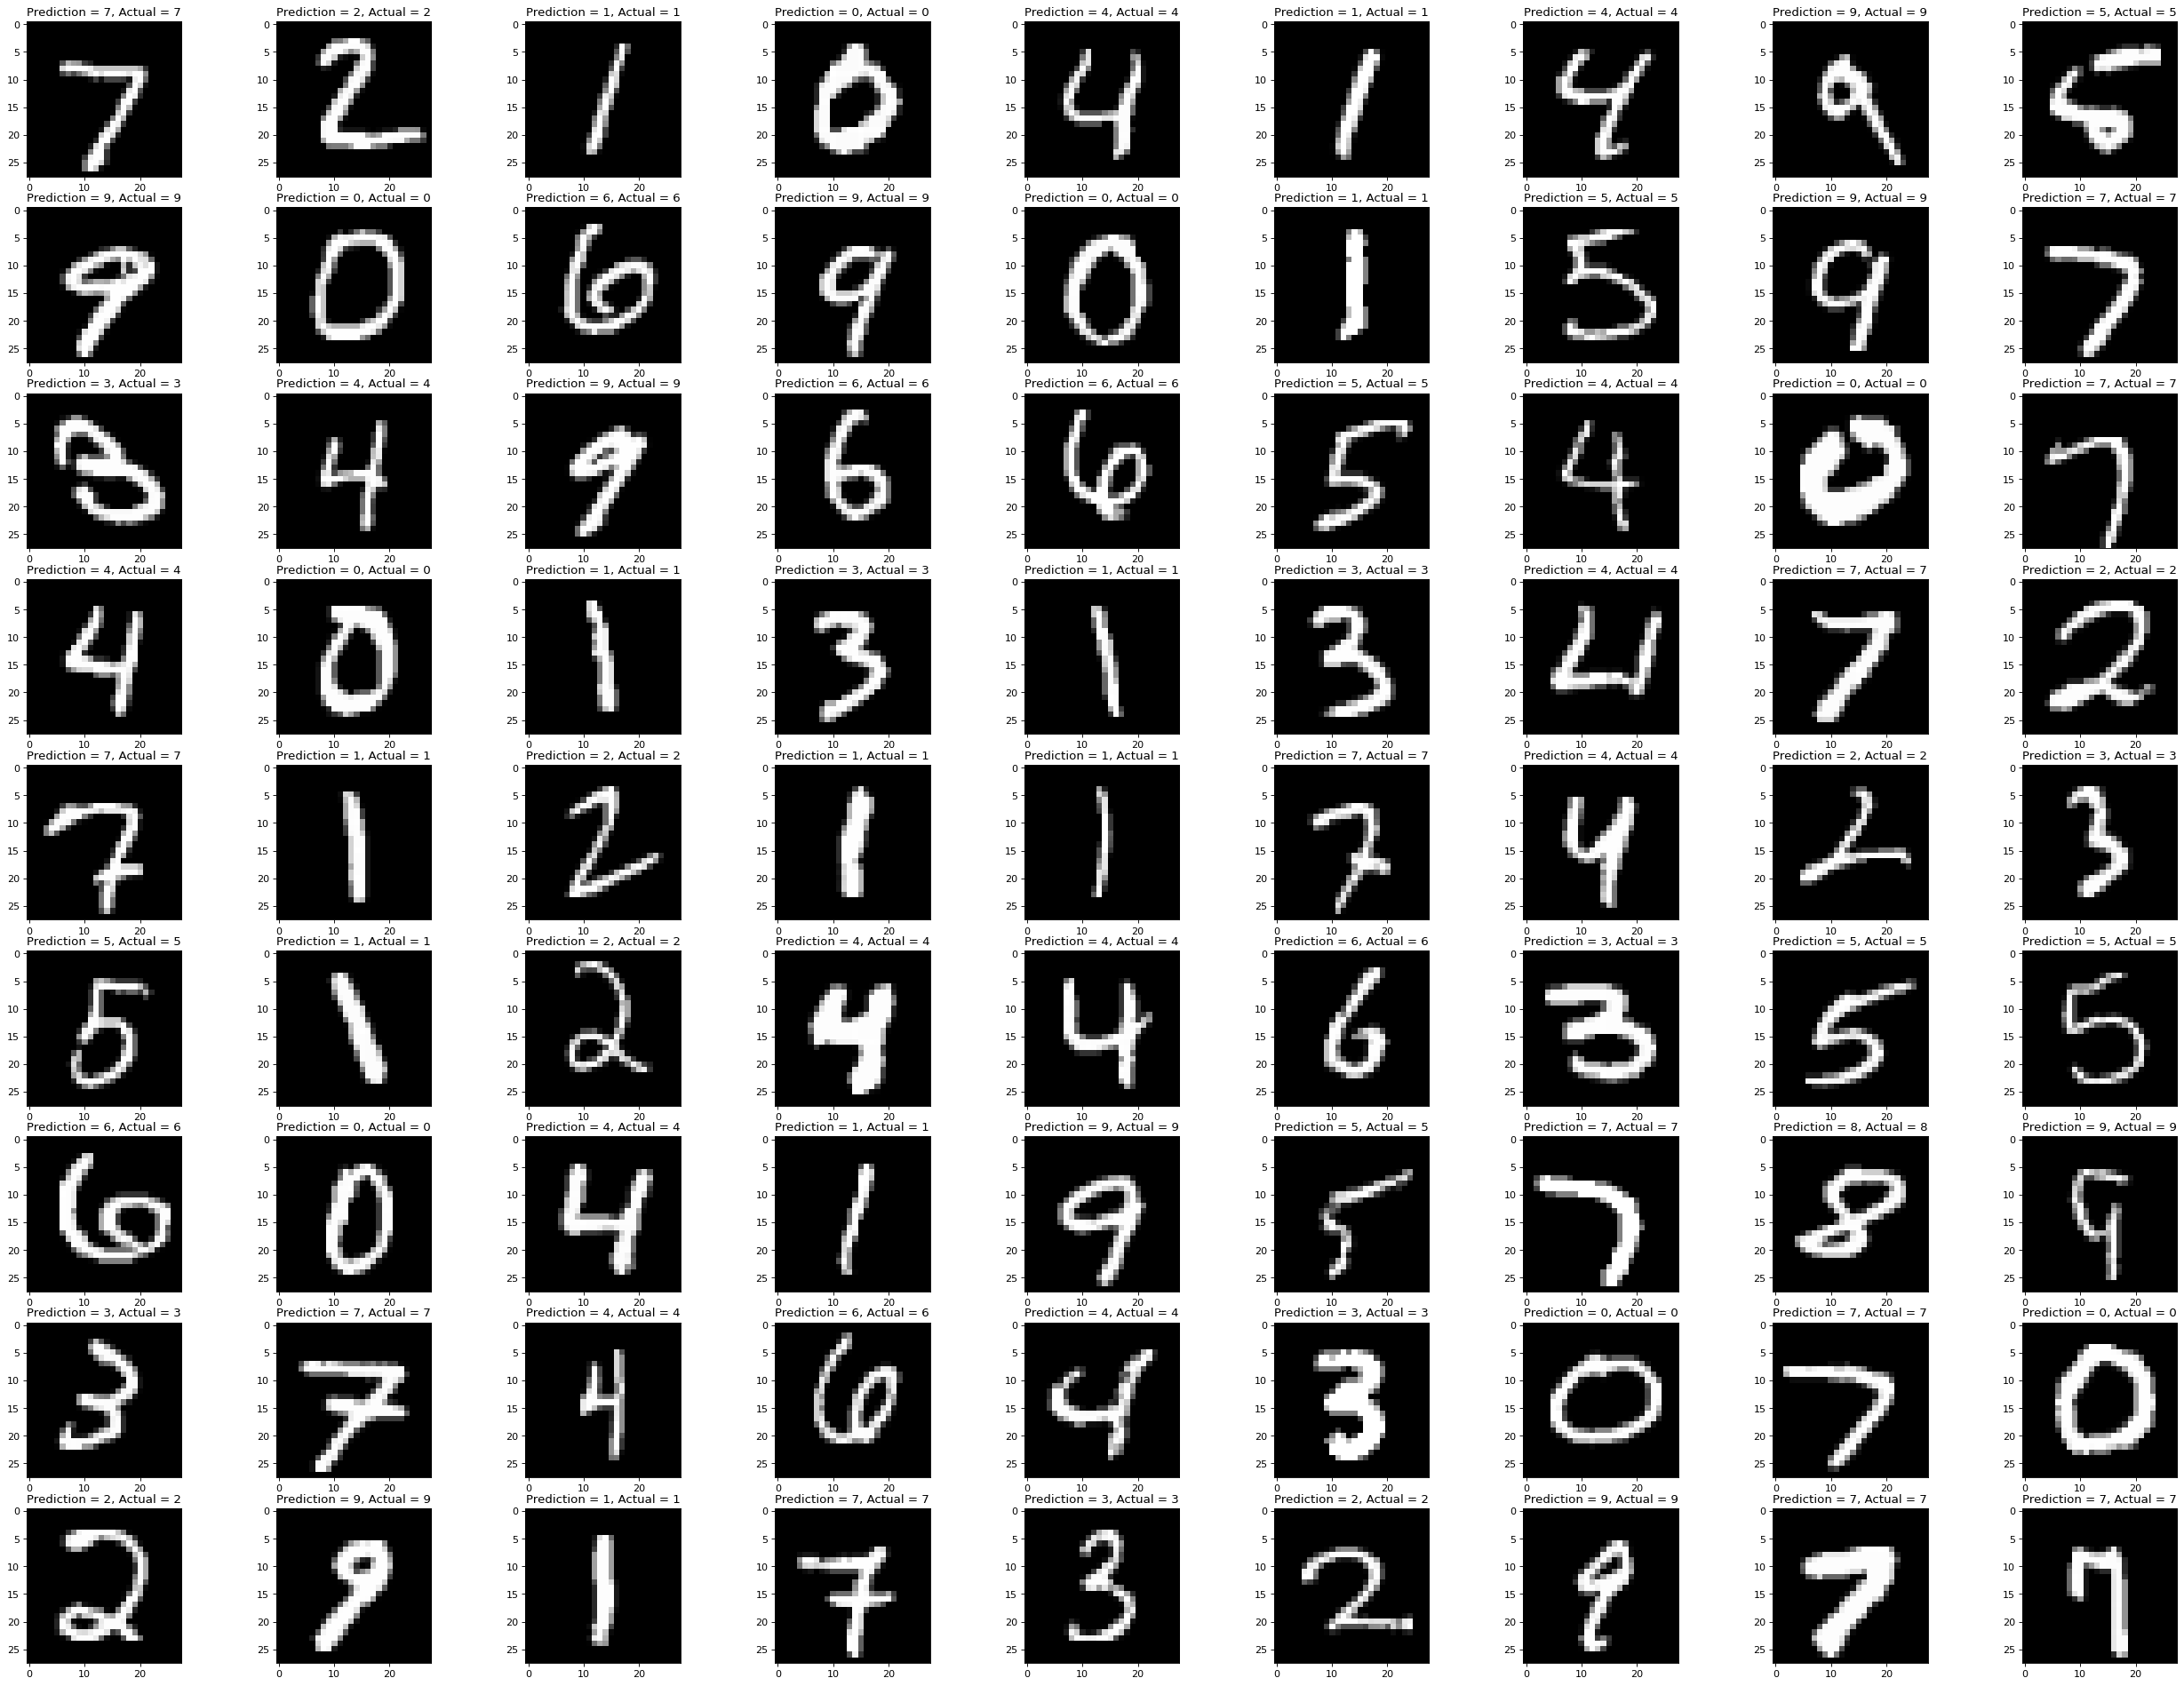

In [39]:
plt.figure(figsize=(40,30), dpi= 80, facecolor='w', edgecolor='k')

for i, correct in enumerate(correct_indices[:81]):
    plt.subplot(9,9,i+1)
    plt.imshow(x_test[correct].reshape(28,28), cmap='gray', interpolation='none')
    plt.title("Prediction = {}, Actual = {}".format(y_pred[correct], y_test[correct]))   


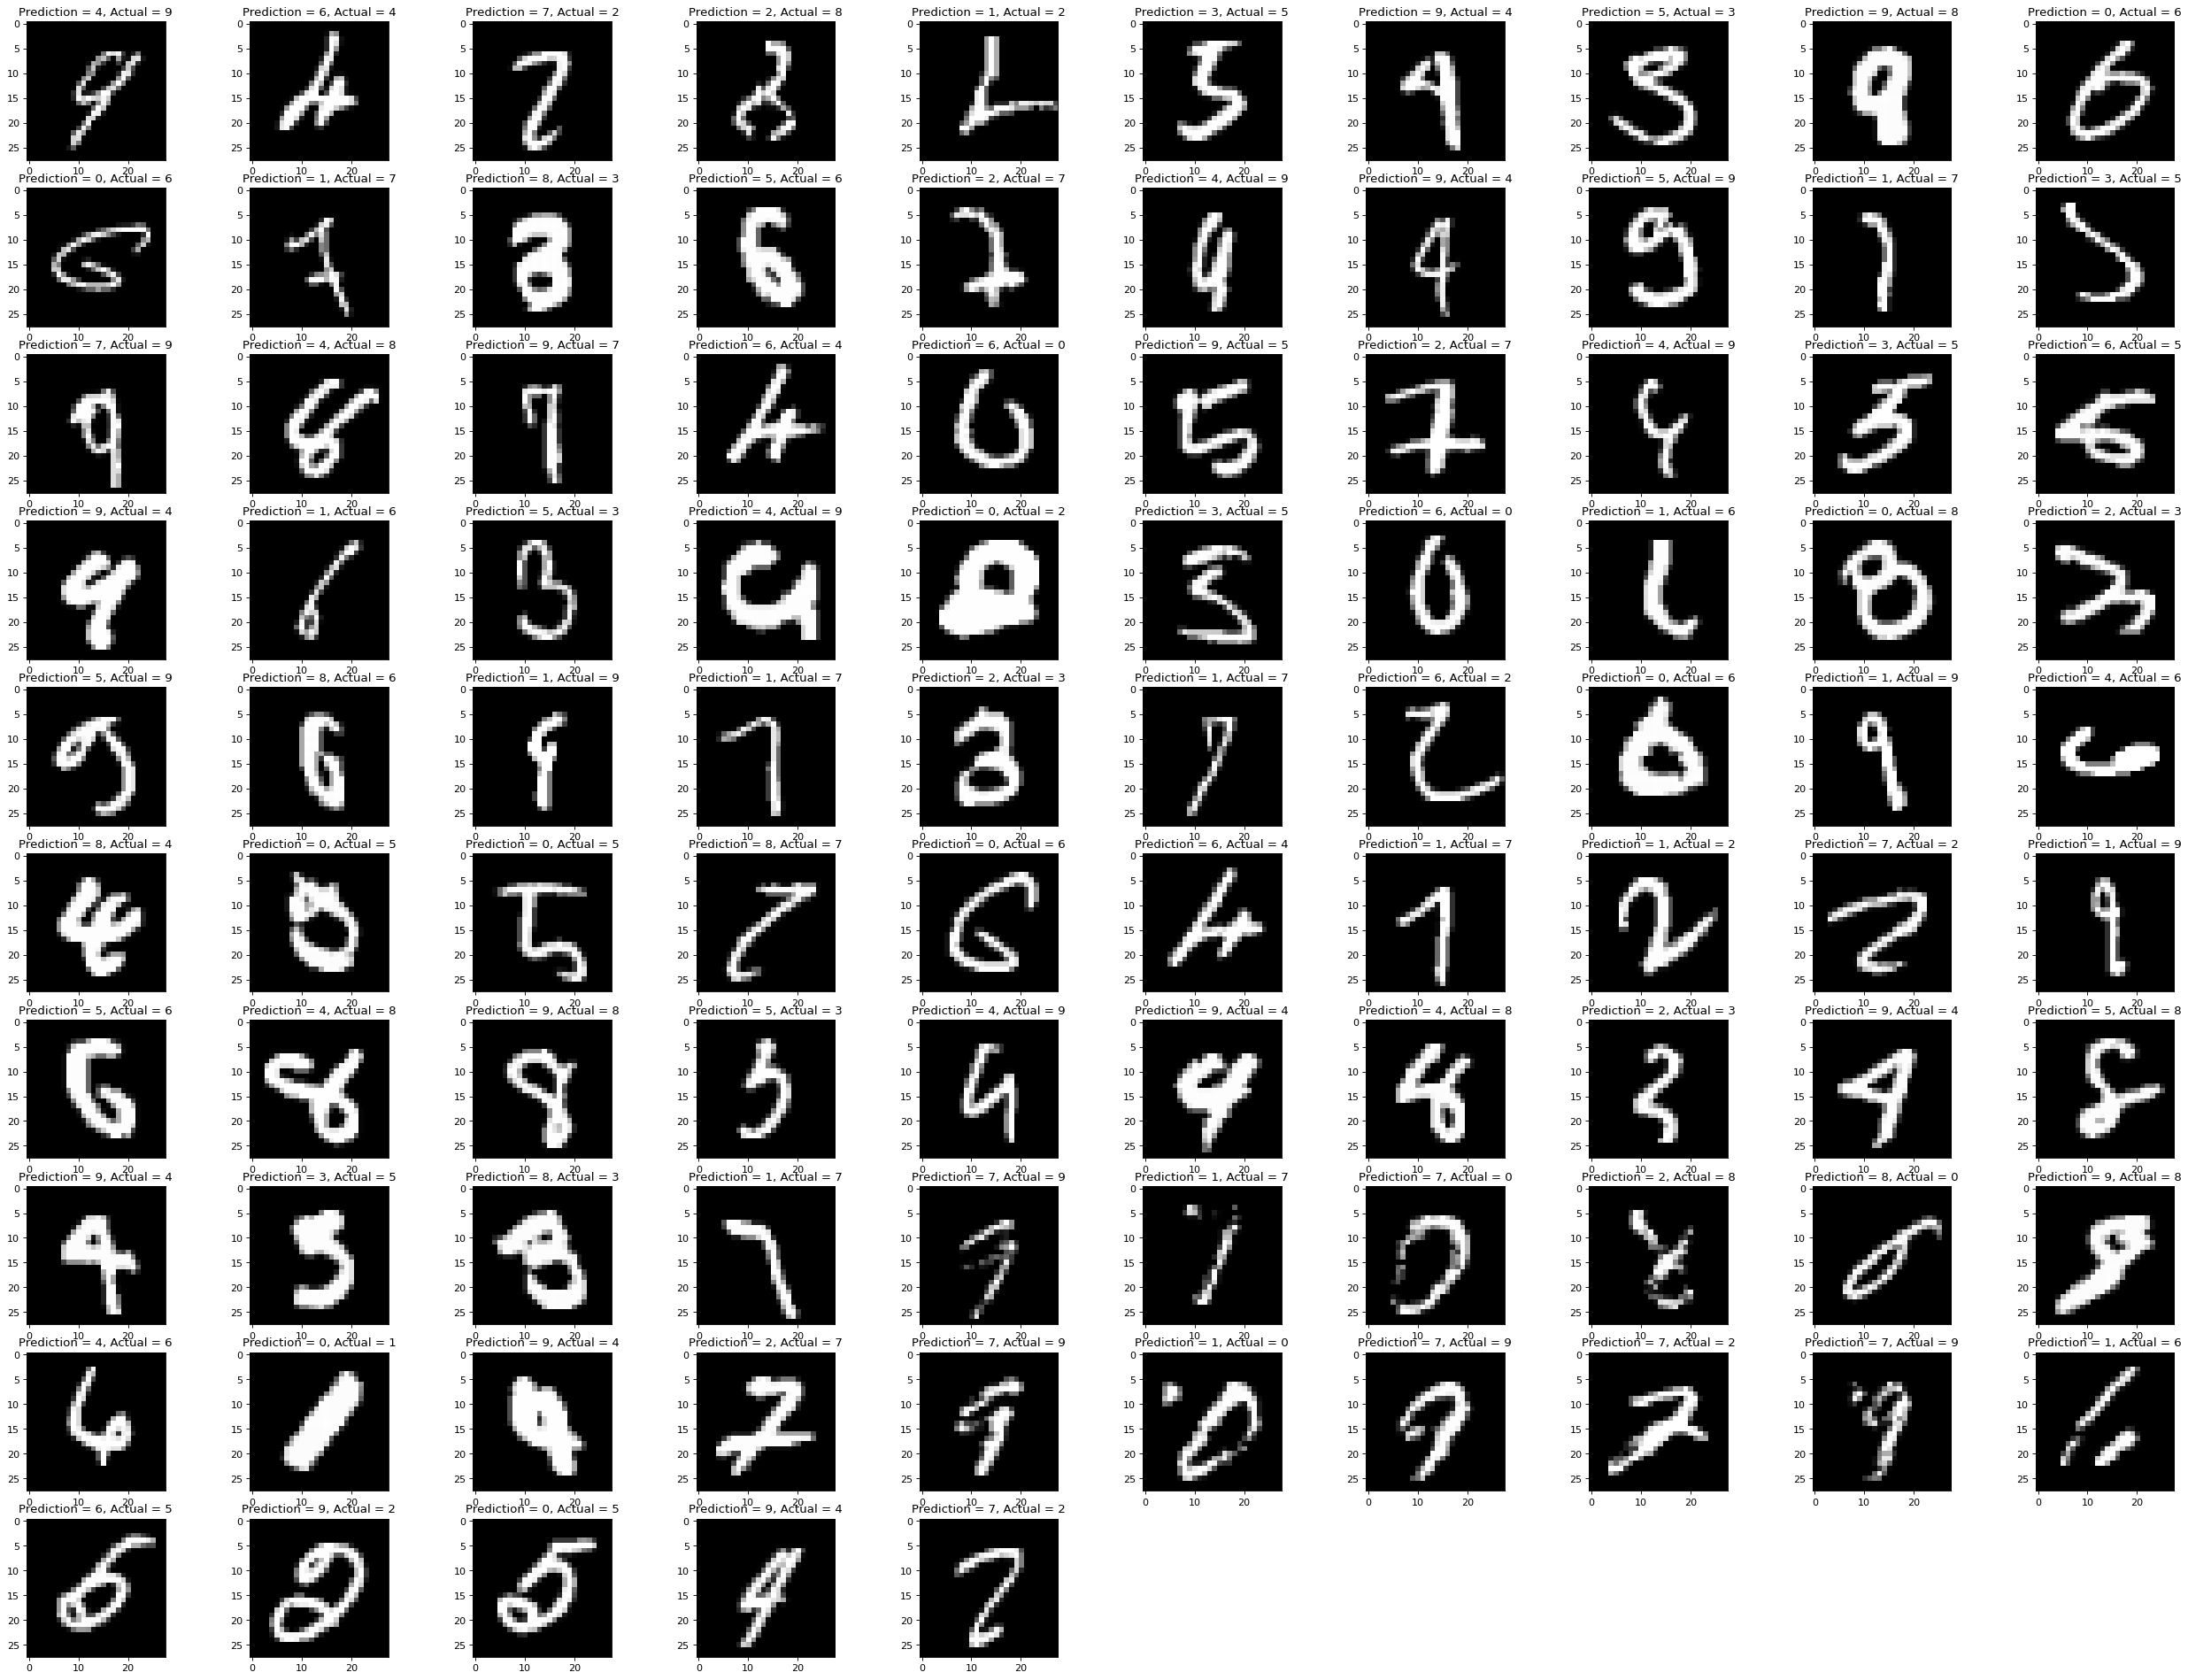

In [40]:
plt.figure(figsize=(40,30), dpi= 80, facecolor='w', edgecolor='k')

for i, incorrect in enumerate(incorrect_indices[:100]):
    plt.subplot(10,10,i+1)
    plt.imshow(x_test[incorrect].reshape(28,28), cmap='gray', interpolation='none')
    plt.title("Prediction = {}, Actual = {}".format(y_pred[incorrect], y_test[incorrect]))   
